# Citi Bike Avalibility Predictor

Performing EDA and model training and testing

### Import Libraries

In [1]:
import pandas as pd
from zoneinfo import ZoneInfo
from datetime import datetime as dt, timezone, timedelta
import holidays
import seaborn as sns
import json
import meteostat as ms
import numpy as np

### Import station data
Map each station's 'shortname' to their important features

In [4]:
stations_df = pd.read_csv('All_Data/Station_Info/citibike-stations.csv')
id_to_shortname = dict(zip(stations_df['station_id'], stations_df['short_name']))
id_to_lat = dict(zip(stations_df['station_id'], stations_df['lat']))
id_to_lon = dict(zip(stations_df['station_id'], stations_df['lon']))
id_to_name = dict(zip(stations_df['station_id'], stations_df['name']))
shortname_to_name = dict(zip(stations_df['short_name'], stations_df['name']))

In [45]:
stations_df.head()

,capacity,eightd_has_key_dispenser,electric_bike_surcharge_waiver,external_id,has_kiosk,lat,lon,name,region_id,rental_methods,rental_url,short_name,station_id
0,66,True,False,66db5fae-0aca-11e7-82f6-3863bb44ef7c,True,40.764397,-73.973715,Grand Army Plaza & Central Park S,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6839.1,281
1,33,True,False,66db6da2-0aca-11e7-82f6-3863bb44ef7c,True,40.704633,-74.013617,Broadway & Battery Pl,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,4962.01,304
2,64,False,False,66dbc982-0aca-11e7-82f6-3863bb44ef7c,True,40.755103,-73.974987,E 47 St & Park Ave,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6584.12,359
3,45,False,False,66dbe441-0aca-11e7-82f6-3863bb44ef7c,True,40.722438,-74.005664,6 Ave & Canal St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5500.07,377
4,36,False,False,66dbe601-0aca-11e7-82f6-3863bb44ef7c,True,40.734927,-73.992005,University Pl & E 14 St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5905.11,382


## Data Pipeline

### Final Pipeline

Implemented Basic Time and Location Features

In [13]:
df_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'IsRushHour','timestamp','minute'
                #    ,'temp','prcp','snwd','wspd','time_since_rain','time_since_dry'
                   ]



def add_features(df):
    
    df = df.drop('station_status_last_reported', axis=1)

    df['Month'] = df['timestamp'].dt.month
    df['Day'] = df['timestamp'].dt.dayofweek
    df['Hour'] = df['timestamp'].dt.hour
    df['IsWeekend'] = df['Day'].isin([5,6]).astype(int)
    df['lat'] = df['station_id'].map(id_to_lat)
    df['lon'] = df['station_id'].map(id_to_lon)
    df['minute'] = df['timestamp'].dt.minute
    df['percentage_available'] = df['num_bikes_available'] / (df['num_bikes_available'] + df['num_docks_available'])
    df['IsRushHour'] = ((df['Hour'].isin([7,8,9,16,17,18])) & (df['IsWeekend'] == 0)).astype(int)
    df['shortname'] = df['station_id'].map(id_to_shortname)


    ny_holidays = holidays.US(state='NY')
    holiday_date_list = list(ny_holidays.keys())

    df['IsHoliday'] = df['timestamp'].dt.date.isin(holiday_date_list).astype(int)
    df['IsNonWorkingDay'] = ((df['IsWeekend'] == 1) | (df['IsHoliday'] == 1)).astype(int)
    # df = add_weather(df)

    return df

def process_file(csv_file):
    df = pd.read_parquet(csv_file)
    df['timestamp'] = df['station_status_last_reported']
    
    df = add_features(df)

    print(f"Before dropping NA: {df.shape[0]} rows")
    # I actually have no idea about this isna() vs isnan bug
    df.loc[np.isnan(df['percentage_available']), 'percentage_available'] = pd.NA
    df = df[df_columns + ['percentage_available']].dropna()
    print(f"After dropping NA: {df.shape[0]} rows")
    df['shortname'] = df['shortname'].astype('category')

    

    return df
    

### Some Feature Experimentation

- **Tested a station volitatity feature**: The idea was for the trees to spend less splits finding stations that had predicting patterns. 
  The model ended up performing worse though (mostly due to poor implemention of the features), but just running more iterations
  to construct a deeper tree is sufficient

- **Potential Weather feature**: I considered adding a weather feature, relying on weather forecast (will implement later)

- **Potential Lag Features**: Maybe later as well but not sure how significant this will be


In [4]:
def add_vol(df):

    hourly_variances = df.groupby(['station_id', 'Hour'])['percentage_available'].var()
    station_volatility = hourly_variances.groupby(level=0).mean()
    df['Volatility'] = df['station_id'].map(station_volatility)
    return df;

In [8]:
df_weather = pd.read_parquet('All_Data/Weather_Data/weather_data.parquet')

In [7]:

def add_weather(df):
    df['hour_key'] = df['timestamp'].dt.floor('h')

    # time since rain feature??
    last_rain = df_weather.iloc[0]['time']
    time_since_rain = []
    for i in range(len(df_weather)):
        curr = df_weather.iloc[i]
        if curr['prcp'] > 0:
            last_rain = curr['time']
        time_since_rain.append((curr['time'] - last_rain).total_seconds())

    # time since dry feature??
    last_dry = df_weather.iloc[0]['time']
    time_since_dry = []
    for i in range(len(df_weather)):
        curr = df_weather.iloc[i]
        if not (curr['prcp'] > 0 or curr['snwd'] > 0):
            last_dry = curr['time']
        time_since_dry.append((curr['time'] - last_dry).total_seconds())



    df_weather['time_since_rain'] = time_since_rain
    df_weather['time_since_dry'] = time_since_dry
    

    df_final = pd.merge(
    df, 
    df_weather, 
    left_on='hour_key', 
    right_on='time', 
    how='left'       
    )

    return df_final

## XG Boost Model Training + Testing

- XGBoost chosen for non-linearity and incapasulating complex feature relationships
- Used CatBoost for categorical importance of distinguishing between individual station trends

### Import Libraries

In [ ]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")


/home/tris123/miniconda3/envs/citi-bike/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Create train and validation sets

- Used a simple validation setup: years **2017 to 2018** for training and year **2019** for validation (omitted 2020, 2021 for COVID and 2016 for the system being in an earlier stage)
- Trained the model out a randomly sampled subset of the total collected data due to RAM limitations

In [ ]:
df = process_file('All_Data/Cleaned/medium_2017-2018_100,000per.parquet')
feature_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'IsRushHour','minute'
                  #  ,'temp','prcp','snwd','wspd','time_since_rain','time_since_dry'
                   ]


X_train = df[feature_columns]
y_train = df['percentage_available']

Before dropping NA: 266490 rows
After dropping NA: 265988 rows


In [16]:
val_dataset = process_file('All_Data/Cleaned/large_2019_500,000per.parquet')
X_val = val_dataset[feature_columns]
y_val = val_dataset['percentage_available']

Before dropping NA: 666945 rows
After dropping NA: 666377 rows


In [31]:
def evaluate_model(predicted, actual):
    train_mae = mean_absolute_error(predicted, actual)
    train_rmse = np.sqrt(mean_squared_error(predicted, actual))
    train_r2 = r2_score(predicted, actual)

    print(f"  MAE:  {train_mae:.4f}")
    print(f"  RMSE: {train_rmse:.4f}")
    print(f"  R²:   {train_r2:.4f}")

## Model Training

In [18]:
print("Training XGBoost model...")

mlflow.set_experiment("mlflow_test")
mlflow.autolog()

with mlflow.start_run(run_name = 'Baseline_Autolog'):
    params = {
        'iterations':500,
        'learning_rate': 0.03,
        'depth':6,
        'loss_function':'RMSE',
        'eval_metric':'RMSE',
        'random_seed':42,
        'verbose':100
    }

    mlflow.log_params(params)

    baseline_model = CatBoostRegressor(**params)

    baseline_model.fit(X_train, y_train, cat_features=['shortname', 'Month','Day'], eval_set=(X_val, y_val))

    y_train_pred = baseline_model.predict(X_train)
    y_val_pred = baseline_model.predict(X_val)

    train_mae = mean_absolute_error(y_train, y_train_pred)
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    train_r2 = r2_score(y_train, y_train_pred)

    val_mae = mean_absolute_error(y_val, y_val_pred)
    val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
    val_r2 = r2_score(y_val, y_val_pred)

    mlflow.log_metric("train_mae", train_mae)
    mlflow.log_metric("train_rmse", train_rmse)
    mlflow.log_metric("train_r2", train_r2)

    mlflow.log_metric("val_mae", val_mae)
    mlflow.log_metric("val_rmse", val_rmse)
    mlflow.log_metric("val_r2", val_r2)


    print("\n=== Baseline Model Performance ===")
    print(f"\nTraining Set:")
    print(f"  MAE:  {train_mae:.4f}")
    print(f"  RMSE: {train_rmse:.4f}")
    print(f"  R²:   {train_r2:.4f}")

    print(f"\nValidation Set:")
    print(f"  MAE:  {val_mae:.4f}")
    print(f"  RMSE: {val_rmse:.4f}")
    print(f"  R²:   {val_r2:.4f}")

    mlflow.set_tag('Baseline', 'Used 100,000 per dataset with 500,000 crossval(default?)')




Training XGBoost model...


2026/03/05 17:20:15 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.


0:	learn: 0.3369749	test: 0.3353480	best: 0.3353480 (0)	total: 253ms	remaining: 2m 6s
100:	learn: 0.2606813	test: 0.3026777	best: 0.3002781 (45)	total: 7.59s	remaining: 30s
200:	learn: 0.2505233	test: 0.3006377	best: 0.3002781 (45)	total: 20.3s	remaining: 30.1s
300:	learn: 0.2457282	test: 0.2994841	best: 0.2994128 (299)	total: 36.5s	remaining: 24.1s
400:	learn: 0.2431375	test: 0.2991857	best: 0.2991224 (384)	total: 50.7s	remaining: 12.5s
499:	learn: 0.2408091	test: 0.2988519	best: 0.2988013 (478)	total: 1m 6s	remaining: 0us

bestTest = 0.2988013374
bestIteration = 478

Shrink model to first 479 iterations.

=== Baseline Model Performance ===

Training Set:
  MAE:  0.1885
  RMSE: 0.2342
  R²:   0.5253

Validation Set:
  MAE:  0.2411
  RMSE: 0.2988
  R²:   0.1794


### Confirmation Validation Test with full data for a few stations
- Just a sanity check

In [114]:


X_smallval = df_viz[feature_columns]
y_smallval = df_viz['percentage_available']

y_smallval_pred = baseline_model.predict(X_smallval)


val_mae = mean_absolute_error(y_smallval, y_smallval_pred)
val_rmse = np.sqrt(mean_squared_error(y_smallval, y_smallval_pred))
val_r2 = r2_score(y_smallval, y_smallval_pred)

print(f"\nSmall Validation Set:")
print(f"  MAE:  {val_mae:.4f}")
print(f"  RMSE: {val_rmse:.4f}")
print(f"  R²:   {val_r2:.4f}")


Small Validation Set:
  MAE:  0.2449
  RMSE: 0.3066
  R²:   0.1103


In [42]:
baseline_model.save_model('Weather_Model.cbm')



### Model Performance Logs
- Code used to track the performance of different test models, stored logs in csv

In [41]:

model_logs = pd.read_csv('model_logs.csv')
model_logs.loc[len(model_logs)] = pd.Series({
    'model_name': '3500 iter, 9 tree depth??',
    'train_mae': val_mae,
    'train_rmse': val_rmse,
    'R^2': val_r2,
    'hyperparams': '3500 iterations, 0.7 learning, 9 depth',
    'features_used': 'weather + time since rain + time since dry',
    'notes': 'tree depth might still need to be higher, satified with this for now since training takes so long'
})

model_logs.to_csv('model_logs.csv', index=False)

In [39]:
model_logs = pd.read_csv('model_logs.csv')
pd.set_option('display.max_colwidth', None)
model_logs

,model_name,train_mae,train_rmse,R^2,hyperparams,features_used,notes
0,Baseline CatBoost,0.143460,0.187209,0.624322,default,"NO lag features, baseline","Default parameters, seems kinda weak, ran on medium sized dataset with just sparse data from the first 2 csvs"
1,Cat Boost with first before time stamp lag,0.019427,0.044316,0.978949,default,Only lag from previous measurement and time since last measurement,"Pretty good but I feel like the predictive power is limited since the lags are so close, will have to figure out better lag design"
2,Standard with more data and from 2017 and 2018,0.163594,0.210014,0.515280,"default, will change to 500 iteration since conversion seems to be at around 200",Standard,uhhh i feel like more data had a very marginal improvement
3,Standard with more data and from 2017 and 2018,0.215938,0.277457,0.243575,default,Standard,oops will start logging test results from now on
4,"Standard using only stations in Manhatten under 14th st. Used 2017 to 2018 data with 100,000 cols per csv, used 10,000 per csv for cross val",0.202173,0.256919,0.419616,default,"Standard, added volitatity",lowkey using used stations make big difference
5,"same as previous but I took out volitatiy, turned out to be bad i guess",0.200971,0.255792,0.424698,default,Standard,lowkey using used stations make big difference
6,added minute feature,0.201037,0.255623,0.425459,default,Standard + minute,literally no difference i guess will keep in the model
7,changed max iterations to 1000,0.197427,0.253156,0.436494,default,Standard,"lowkey max iterations makes a gud difference, model is still underfitting and could be better with more"
8,"used dataset with 500,000 rows by per csv",0.173122,0.217899,0.582525,default,Standard,holy shit more data actually matters so much
9,"upgraded to 1,500 iterations",0.169426,0.214200,0.596577,default,Standard,"still underfit but gains were minial, 10 minutes to train"


## Prediction Visualization

- Predict on the same 2 stations: **Mercer & Spring St** and **7th St & Avenue A**
- **RED**: Predicted Values
- **BLUE**: Actual Values

- After more throurough testing, the model doesn't seem like to commit to extreme values for 0 or 1. This is probrably just due to the nature of decision trees, but
  it's unfortunate since those are the 2 most common capacities. This is especially problematic for current 2026 predictions where increase ridership has increased how
  common these extremes occur. Not sure how to address this

Mercer St & Spring St :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

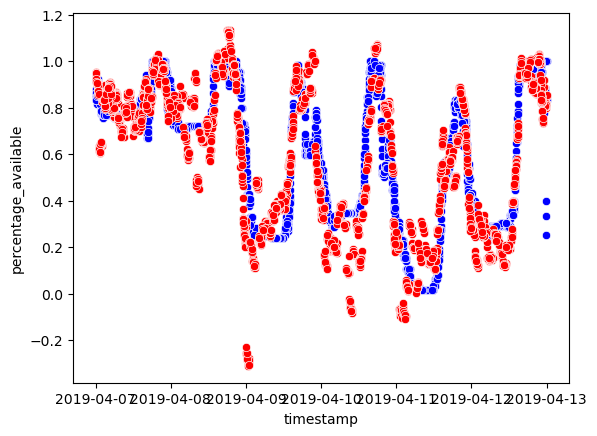

In [45]:

val_dataset['predictions'] = y_smallval_pred

SHORTNAME = '5532.01'

timeframe_graphed = (val_dataset['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (val_dataset['timestamp'] < dt(2019,4,13, tzinfo = timezone.utc))

print(shortname_to_name[SHORTNAME], ':')


sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='predictions', color = 'red')



Mercer St & Spring St :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

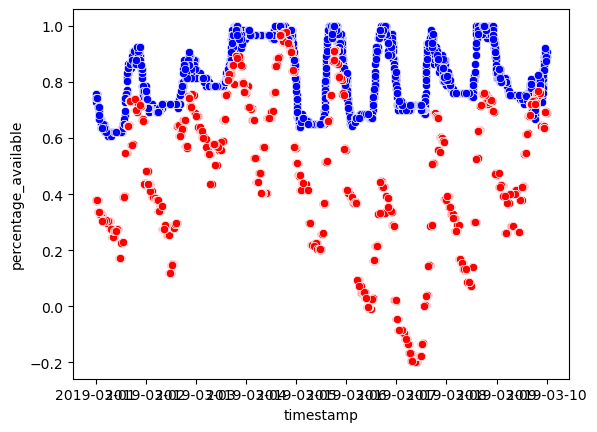

In [115]:

df_viz['predictions'] = y_smallval_pred

SHORTNAME = '5532.01'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,3,1, tzinfo = timezone.utc)) & (df_viz['timestamp'] < dt(2019,3,10, tzinfo = timezone.utc))

print(shortname_to_name[SHORTNAME], ':')


sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='predictions', color = 'red')



E 7 St & Avenue A :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

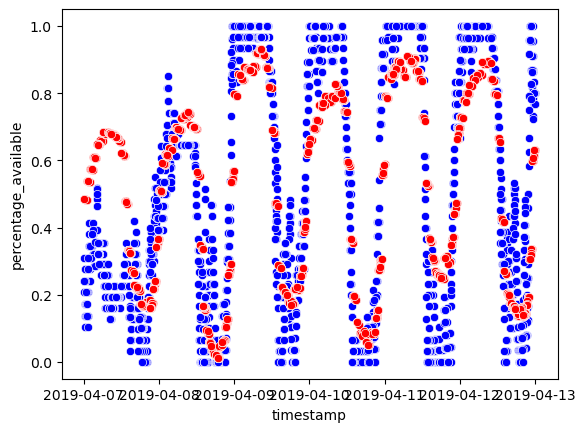

In [116]:

df_viz['predictions'] = y_smallval_pred

SHORTNAME = '5626.07'

timeframe_graphed = (df_viz['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (df_viz['timestamp'] < dt(2019,4,13, tzinfo = timezone.utc))

print(shortname_to_name[SHORTNAME], ':')


sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
sns.scatterplot(data= df_viz[(df_viz['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='predictions', color = 'red')



E 7 St & Avenue A :


<Axes: xlabel='timestamp', ylabel='percentage_available'>

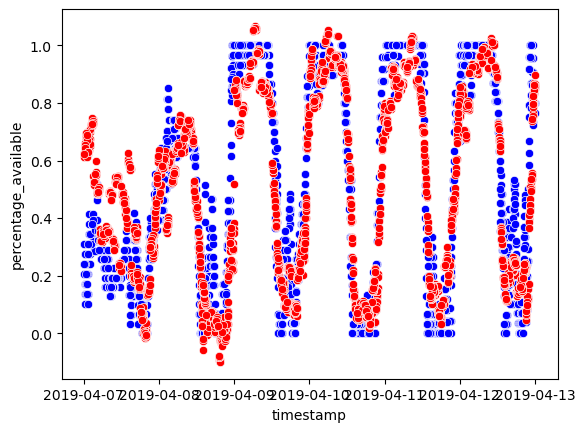

In [46]:
SHORTNAME = '5626.07'

timeframe_graphed = (val_dataset['timestamp'] >= dt(2019,4,7, tzinfo = timezone.utc)) & (val_dataset['timestamp'] < dt(2019,4,13, tzinfo = timezone.utc))

print(shortname_to_name[SHORTNAME], ':')


sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')
sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == SHORTNAME) & timeframe_graphed], x='timestamp', y='predictions', color = 'red')


### Quick Baseline Comparison Test

This below model just predicts the 2019 based on the capacities of the same date in 2018.
I tested this model out of curiosity to see how effective my XG Boost, it serves as another baseline to compare to.

The simple "last year" model performed terribly, much worse than I would have thought

In [36]:
df_2018 = df[(df['timestamp'] >= dt(2018,1,1, tzinfo = timezone.utc)) & (df['timestamp'] < dt(2018,12,31, tzinfo = timezone.utc))]
df_2018 = df_2018.sort_values('timestamp')
df_2019 = val_dataset
df_2019 = df_2019.sort_values('timestamp')
df_2019['last_year_time'] = df_2019['timestamp'] - timedelta(days = 365)

df_lag = pd.merge_asof(
    df_2019,
    df_2018[["shortname","timestamp", "percentage_available"]],
    left_on="last_year_time",
    right_on="timestamp",
    direction="backward",
    by = 'shortname',
    suffixes=("", "_lag_1h")
)

df_lag = df_lag.dropna(subset=["percentage_available_lag_1h"])





In [38]:
print("Evaluating simple year back model:")
evaluate_model(df_lag['percentage_available'], df_lag['percentage_available_lag_1h'])

Evaluating simple year back model:
  MAE:  0.3467
  RMSE: 0.4380
  R²:   -0.7736


## Construct Final Model

- Train on combined 2017 - 2019 data